In [1]:
import sklearn
import scipy as sp
import pandas as pd
import numpy as np

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder

import matplotlib.pyplot as plt
from scipy.stats import zscore
from sklearn.preprocessing import StandardScaler, MinMaxScaler

#Exercise 1: Load the Titanic dataset and check for duplicates

#import file
# Read the Titanic CSV file into a pandas DataFrame
df = pd.read_csv("train.csv")


# Count the number of duplicate rows across all columns
num_duplicates = df.duplicated().sum()

print(f"Number of duplicates before removal: {num_duplicates}")

# Display any duplicate rows
duplicate_rows = df[df.duplicated(keep=False)]

print("\nDuplicate rows:")
print(duplicate_rows)

# Remove duplicate rows
df_clean = df.drop_duplicates()

# Verify that duplicates have been removed
remaining_duplicates = df_clean.duplicated().sum()

print(f"\nNumber of duplicates after removal: {remaining_duplicates}")

# Compare row counts before and after
print(f"\nOriginal number of rows: {len(df)}")
print(f"Number of rows after removing duplicates: {len(df_clean)}")


Number of duplicates before removal: 0

Duplicate rows:
Empty DataFrame
Columns: [PassengerId, Survived, Pclass, Name, Sex, Age, SibSp, Parch, Ticket, Fare, Cabin, Embarked]
Index: []

Number of duplicates after removal: 0

Original number of rows: 891
Number of rows after removing duplicates: 891


In [ ]:
#Exercise 2: Check for missing values in the Titanic dataset
from sklearn.impute import SimpleImputer
# Count missing values in each column
missing_values = df.isnull().sum()

print("Missing values by column:")
print(missing_values)

# Display only columns that contain missing values
print("\nColumns with missing values:")
print(missing_values[missing_values > 0])

# Remove rows with missing values
df = df.dropna()

# Create a copy so the original dataset remains unchanged
df_dropna = df.copy()

# Remove rows containing ANY missing values
df_dropna = df_dropna.dropna()

print(
    f"\nNumber of rows after dropna(): {len(df_dropna)}"
)

# Create another copy
df_fillna = df.copy()

# Replace missing Cabin values with a constant string
df_fillna["Cabin"] = df_fillna["Cabin"].fillna("Unknown")

# Replace missing Embarked values with a constant value
df_fillna["Embarked"] = df_fillna["Embarked"].fillna("Missing")

print("\nMissing values after fillna():")
print(df_fillna[["Cabin", "Embarked"]].isnull().sum())

# Note: This approach is useful for categorical columns where "Unknown" or "Missing" is meaningful.

# Create another copy
df_imputed = df.copy()

# Create an imputer that replaces missing values with the median of the column
age_imputer = SimpleImputer(strategy="median")

# Fit the imputer and replace missing Age values
df_imputed["Age"] = age_imputer.fit_transform(
    df_imputed[["Age"]]
)

print("\nMissing Age values after imputation:")
print(df_imputed["Age"].isnull().sum())

# Median is often preferred for Age because it is less affected by extreme values than the mean.

# Create a final cleaned dataset
df_clean = df.copy()

# Fill missing Cabin values with a constant
df_clean["Cabin"] = df_clean["Cabin"].fillna("Unknown")

# Impute Age with the median value
age_imputer = SimpleImputer(strategy="median")
df_clean["Age"] = age_imputer.fit_transform(
    df_clean[["Age"]]
)

# Remove rows where Embarked is missing
df_clean = df_clean.dropna(subset=["Embarked"])

print("\nRemaining missing values in cleaned dataset:")
print(df_clean.isnull().sum())

print(f"\nNumber of rows in cleaned dataset: {len(df_clean)}")


Missing values by column:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Columns with missing values:
Age         177
Cabin       687
Embarked      2
dtype: int64

Number of rows after dropna(): 183

Missing values after fillna():
Cabin       0
Embarked    0
dtype: int64

Missing Age values after imputation:
0

Remaining missing values in cleaned dataset:
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Cabin          0
Embarked       0
dtype: int64

Number of rows in cleaned dataset: 183


In [3]:
#Exercise 3: Feature engineering

# SibSp = number of siblings/spouses aboard
# Parch = number of parents/children aboard
#
# Adding 1 includes the passenger themselves in the family size count

df["FamilySize"] = df["SibSp"] + df["Parch"] + 1

# Verify the new feature was created
print("\nFamilySize feature:")
print(df[["SibSp", "Parch", "FamilySize"]].head())

# EXTRACT TITLES FROM NAMES

# Extract the title (Mr, Mrs, Miss, etc.)
df["Title"] = df["Name"].str.extract(r",\s*([^\.]+)\.")

# Display a sample of extracted titles
print("\nExtracted Titles:")
print(df[["Name", "Title"]].head())


# Count the number of each title
print("\nTitle Counts:")
print(df["Title"].value_counts())

#Convert categorical variables to numbers

# Convert the Sex column into multiple binary columns.
sex_encoded = pd.get_dummies(
    df["Sex"],
    prefix="Sex"
)

# Add encoded columns to the dataset
df = pd.concat([df, sex_encoded], axis=1)

print("\nOne-Hot Encoded Sex columns:")
print(df[["Sex", "Sex_female", "Sex_male"]].head())

#encode the new title feature

# LabelEncoder converts categories into integers.
# Mr -> 0
# Mrs -> 1
# Miss -> 2

title_encoder = LabelEncoder()

df["TitleEncoded"] = title_encoder.fit_transform(df["Title"])
title_encoder = LabelEncoder()

df["TitleEncoded"] = title_encoder.fit_transform(
    df["Title"]
)

print("\nEncoded Titles:")
print(df[["Title", "TitleEncoded"]].head())


# Display the mapping used by LabelEncoder
print("\nTitle Mapping:")

for title, code in zip(
    title_encoder.classes_,
    range(len(title_encoder.classes_))
):
    print(f"{title} -> {code}")

#Review new features

print("\nDataset Columns:")
print(df.columns)

print("\nPreview of Engineered Dataset:")
print(
    df[
        [
            "Name",
            "FamilySize",
            "Title",
            "TitleEncoded"
        ]
    ].head()
)



FamilySize feature:
    SibSp  Parch  FamilySize
1       1      0           2
3       1      0           2
6       0      0           1
10      1      1           3
11      0      0           1

Extracted Titles:
                                                 Name Title
1   Cumings, Mrs. John Bradley (Florence Briggs Th...   Mrs
3        Futrelle, Mrs. Jacques Heath (Lily May Peel)   Mrs
6                             McCarthy, Mr. Timothy J    Mr
10                    Sandstrom, Miss. Marguerite Rut  Miss
11                           Bonnell, Miss. Elizabeth  Miss

Title Counts:
Title
Mr              81
Miss            44
Mrs             38
Master           7
Dr               3
Major            2
Mlle             2
Mme              1
Lady             1
Sir              1
Col              1
Capt             1
the Countess     1
Name: count, dtype: int64

One-Hot Encoded Sex columns:
       Sex  Sex_female  Sex_male
1   female        True     False
3   female        True     False
6  

Summary statistics before treatment:
count    183.000000
mean      78.682469
std       76.347843
min        0.000000
25%       29.700000
50%       57.000000
75%       90.000000
max      512.329200
Name: Fare, dtype: float64


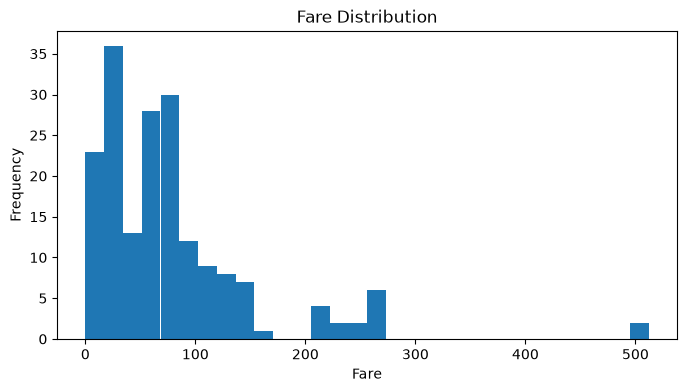

C:\Users\USER1\AppData\Local\Temp\ipykernel_1744\1729325942.py:16: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df["Fare"], vert=False)


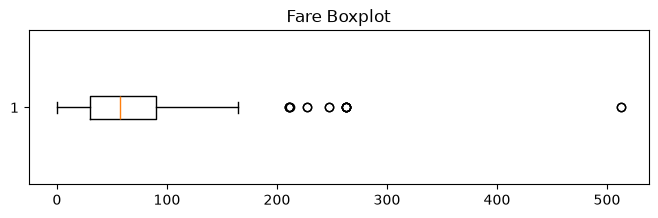


Fare Quantiles:
0.25     29.700000
0.50     57.000000
0.75     90.000000
0.90    153.462500
0.95    245.521220
0.98    263.000000
0.99    307.879256
Name: Fare, dtype: float64

98th percentile Fare value: 263.0

IQR Lower Bound: -60.749999999999986
IQR Upper Bound: 180.45
Number of IQR outliers: 16
Number of Z-score outliers: 2

Maximum Fare after capping:
263.0

Summary statistics after log transformation:
count    183.000000
mean       3.993184
std        0.953260
min        0.000000
25%        3.424263
50%        4.060443
75%        4.510860
max        6.240917
Name: Fare, dtype: float64

Rows before removing outliers: 183
Rows after removing outliers: 167


C:\Users\USER1\AppData\Local\Temp\ipykernel_1744\1729325942.py:107: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df["Fare"], vert=False)
C:\Users\USER1\AppData\Local\Temp\ipykernel_1744\1729325942.py:111: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df_capped["Fare"], vert=False)


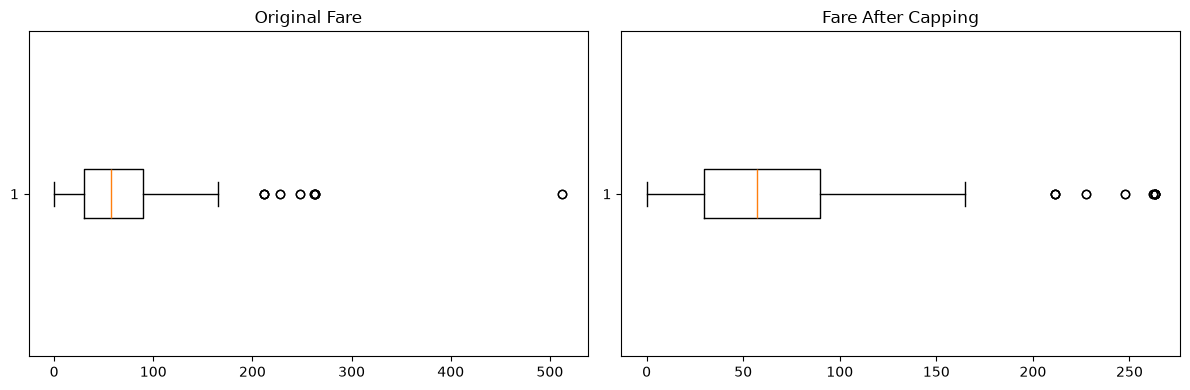


Original Fare Statistics:
count    183.000000
mean      78.682469
std       76.347843
min        0.000000
25%       29.700000
50%       57.000000
75%       90.000000
max      512.329200
Name: Fare, dtype: float64

Capped Fare Statistics:
count    183.000000
mean      75.957560
std       64.252458
min        0.000000
25%       29.700000
50%       57.000000
75%       90.000000
max      263.000000
Name: Fare, dtype: float64


In [4]:
#Exercise 4: Outlier detection and handling
print("Summary statistics before treatment:") # Using Fare as it typically contains several large outliers in the Titanic dataset.
print(df["Fare"].describe())

#Visualising outliers
# Histogram
plt.figure(figsize=(8, 4))
plt.hist(df["Fare"], bins=30)
plt.title("Fare Distribution")
plt.xlabel("Fare")
plt.ylabel("Frequency")
plt.show()

# Boxplot
plt.figure(figsize=(8, 2))
plt.boxplot(df["Fare"], vert=False)
plt.title("Fare Boxplot")
plt.show()

#Exploring quantiles
# Examine percentiles to choose a suitable cap
print("\nFare Quantiles:")
print(df["Fare"].quantile([0.25, 0.5, 0.75, 0.90, 0.95, 0.98, 0.99]))

# Store the 98th percentile
fare_cap = df["Fare"].quantile(0.98)

print(f"\n98th percentile Fare value: {fare_cap}")

#Detecting outliers using IQR
# Calculate quartiles
Q1 = df["Fare"].quantile(0.25)
Q3 = df["Fare"].quantile(0.75)

# Calculate Interquartile Range
IQR = Q3 - Q1

# Define lower and upper bounds
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print(f"\nIQR Lower Bound: {lower_bound}")
print(f"IQR Upper Bound: {upper_bound}")

# Find outliers
iqr_outliers = df[
    (df["Fare"] < lower_bound) |
    (df["Fare"] > upper_bound)
]

print(f"Number of IQR outliers: {len(iqr_outliers)}")

#Detect outliers using Z-score
# Calculate Z-scores
z_scores = zscore(df["Fare"])

# Common threshold = 3
zscore_outliers = df[np.abs(z_scores) > 3]

print(f"Number of Z-score outliers: {len(zscore_outliers)}")

#Quantile capping
# Create a copy
df_capped = df.copy()

# Replace values above 98th percentile with the 98th percentile value
df_capped["Fare"] = np.where(
    df_capped["Fare"] > fare_cap,
    fare_cap,
    df_capped["Fare"]
)

print("\nMaximum Fare after capping:")
print(df_capped["Fare"].max())

#Log transformation then create a copy
df_log = df.copy()

# log1p handles zero values safely
df_log["Fare"] = np.log1p(df_log["Fare"])

print("\nSummary statistics after log transformation:")
print(df_log["Fare"].describe())

#Remove outliers
# Create a copy
df_removed = df.copy()

# Keep only rows within IQR bounds
df_removed = df_removed[
    (df_removed["Fare"] >= lower_bound) &
    (df_removed["Fare"] <= upper_bound)
]

print(
    f"\nRows before removing outliers: {len(df)}"
)

print(
    f"Rows after removing outliers: {len(df_removed)}"
)

#Compare before and after
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.boxplot(df["Fare"], vert=False)
plt.title("Original Fare")

plt.subplot(1, 2, 2)
plt.boxplot(df_capped["Fare"], vert=False)
plt.title("Fare After Capping")

plt.tight_layout()
plt.show()


# Compare key statistics
print("\nOriginal Fare Statistics:")
print(df["Fare"].describe())

print("\nCapped Fare Statistics:")
print(df_capped["Fare"].describe())



In [5]:
#Exercise 5: data standardisation and normalisation
standard_scaler = StandardScaler()

df["Age_Scaled"] = standard_scaler.fit_transform(
    df[["Age"]]
)

print("\nAge after Standard Scaling:")
print(df["Age_Scaled"].describe())

# Min-max scaling

# MinMaxScaler transforms values into the range [0, 1]

minmax_scaler = MinMaxScaler()

df["Fare_Scaled"] = minmax_scaler.fit_transform(
    df[["Fare"]]
)

print("\nFare after Min-Max Scaling:")
print(df["Fare_Scaled"].describe())

# Scale multiple features at once

# If FamilySize exists from your feature engineering step

if "FamilySize" in df.columns:

    df[["FamilySize_Scaled"]] = minmax_scaler.fit_transform(
        df[["FamilySize"]]
    )

    print("\nFamilySize after Min-Max Scaling:")
    print(df["FamilySize_Scaled"].describe())

# Compare before and after scaling for Age and Fare

print("\nOriginal Age Values:")
print(df["Age"].head())

print("\nScaled Age Values:")
print(df["Age_Scaled"].head())

print("\nOriginal Fare Values:")
print(df["Fare"].head())

print("\nScaled Fare Values:")
print(df["Fare_Scaled"].head())

#Check the new dataset

print("\nDataset Columns:")
print(df.columns)

print("\nPreview:")
print(
    df[
        [
            "Age",
            "Age_Scaled",
            "Fare",
            "Fare_Scaled"
        ]
    ].head()
)



Age after Standard Scaling:
count    1.830000e+02
mean    -1.650168e-16
std      1.002743e+00
min     -2.227696e+00
25%     -7.483096e-01
50%      2.086869e-02
75%      7.579979e-01
max      2.841189e+00
Name: Age_Scaled, dtype: float64

Fare after Min-Max Scaling:
count    183.000000
mean       0.153578
std        0.149021
min        0.000000
25%        0.057971
50%        0.111257
75%        0.175668
max        1.000000
Name: Fare_Scaled, dtype: float64

FamilySize after Min-Max Scaling:
count    183.000000
mean       0.187978
std        0.222048
min        0.000000
25%        0.000000
50%        0.200000
75%        0.200000
max        1.000000
Name: FamilySize_Scaled, dtype: float64

Original Age Values:
1     38.0
3     35.0
6     54.0
10     4.0
11    58.0
Name: Age, dtype: float64

Scaled Age Values:
1     0.149065
3    -0.043230
6     1.174636
10   -2.030273
11    1.431029
Name: Age_Scaled, dtype: float64

Original Fare Values:
1     71.2833
3     53.1000
6     51.8625
10    16

In [6]:
#Exercise 6: feature encoding

from sklearn.preprocessing import LabelEncoder

# Identify remaining categorical columns in the dataset after previous encoding steps
# Select all columns with datatype "object"
categorical_columns = df.select_dtypes(
    include=["object"]
).columns

print("\nCategorical Columns:")
print(categorical_columns)

# one-hot encode nominal variables

sex_encoded = pd.get_dummies(
    df["Sex"],
    prefix="Sex",
    dtype=int
)

print("\nEncoded Sex Variables:")
print(sex_encoded.head())

# Encode embarked

embarked_encoded = pd.get_dummies(
    df["Embarked"],
    prefix="Embarked",
    dtype=int
)

print("\nEncoded Embarked Variables:")
print(embarked_encoded.head())

# encode title

title_encoded = pd.get_dummies(
    df["Title"],
    prefix="Title",
    dtype=int
)

print("\nEncoded Titles:")
print(title_encoded.head())

# label encoding
label_encoder = LabelEncoder()

"""
df["PriorityEncoded"] = label_encoder.fit_transform(
    df["Priority"]
)

print("\nPriority Encoding Mapping:")

for category, code in zip(
    label_encoder.classes_,
    range(len(label_encoder.classes_))
):
    print(f"{category} -> {code}")
"""

# merge encoded columns back into the main DataFrame

df = pd.concat(
    [
        df,
        sex_encoded,
        embarked_encoded,
        title_encoded
    ],
    axis=1
)

#remove original categorical columns

df.drop(
    columns=[
        "Sex",
        "Embarked",
        "Title"
    ],
    inplace=True
)
#remove other non-numeric features that are not needed for analysis or modeling

"""
df.drop(
    columns=[
        "Name",
        "Ticket",
        "Cabin"
    ],
    inplace=True
)
"""
#verify results

print("\nUpdated Dataset Columns:")
print(df.columns)

print("\nDataset Shape:")
print(df.shape)

print("\nPreview of Encoded Dataset:")
print(df.head())

#display new features

sex_columns = [
    col for col in df.columns
    if col.startswith("Sex_")
]

print("\nSex Dummy Variables:")
print(df[sex_columns].head())

# display new embarked features

embarked_columns = [
    col for col in df.columns
    if col.startswith("Embarked_")
]

print("\nEmbarked Dummy Variables:")
print(df[embarked_columns].head())

#display new title features
title_columns = [
    col for col in df.columns
    if col.startswith("Title_")
]

print("\nTitle Dummy Variables:")
print(df[title_columns].head())

# final checks
# Verify which categorical variables remain

remaining_categorical = df.select_dtypes(
    include=["object"]
).columns

print("\nRemaining Categorical Columns:")
print(remaining_categorical)



Categorical Columns:
Index(['Name', 'Sex', 'Ticket', 'Cabin', 'Embarked', 'Title'], dtype='str')

Encoded Sex Variables:
    Sex_female  Sex_male
1            1         0
3            1         0
6            0         1
10           1         0
11           1         0

Encoded Embarked Variables:
    Embarked_C  Embarked_Q  Embarked_S
1            1           0           0
3            0           0           1
6            0           0           1
10           0           0           1
11           0           0           1

Encoded Titles:
    Title_Capt  Title_Col  Title_Dr  Title_Lady  Title_Major  Title_Master  \
1            0          0         0           0            0             0   
3            0          0         0           0            0             0   
6            0          0         0           0            0             0   
10           0          0         0           0            0             0   
11           0          0         0           0           

C:\Users\USER1\AppData\Local\Temp\ipykernel_1744\941875483.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(
C:\Users\USER1\AppData\Local\Temp\ipykernel_1744\941875483.py:78: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(
C:\Users\USER1\AppData\Local\Temp\ipykernel_1744\941875483.py:141: Pandas4Warning: For backward compatibility, 'str' dtypes are included by s

In [7]:
#Exercise 7
#define age bins

age_bins = [0, 12, 18, 60, 100]

age_labels = [
    "Child",
    "Teen",
    "Adult",
    "Senior"
]

# Create a new AgeGroup column
df["AgeGroup"] = pd.cut(
    df["Age"],
    bins=age_bins,
    labels=age_labels,
    include_lowest=True
)

# Display a sample
print("\nAge Groups:")
print(df[["Age", "AgeGroup"]].head())

# check age group distribution
# Count how many passengers fall into each group.

print("\nAge Group Counts:")
print(df["AgeGroup"].value_counts())

# one-hot encode age groups
# AgeGroup is a nominal categorical feature

agegroup_encoded = pd.get_dummies(
    df["AgeGroup"],
    prefix="AgeGroup",
    dtype=int
)

print("\nOne-Hot Encoded Age Groups:")
print(agegroup_encoded.head())

# merge encoded colunms

df = pd.concat(
    [df, agegroup_encoded],
    axis=1
)

# remove original age group column 

df.drop(
    columns=["AgeGroup"],
    inplace=True
)

# verify results

print("\nDataset Columns:")
print(df.columns)

print("\nEncoded Age Group Features:")

agegroup_columns = [
    col for col in df.columns
    if col.startswith("AgeGroup_")
]

print(df[agegroup_columns].head())

# preview results

print("\nPreview of Age Group Variables:")

print(
    df[
        [
            "Age",
            "AgeGroup_Child",
            "AgeGroup_Teen",
            "AgeGroup_Adult",
            "AgeGroup_Senior"
        ]
    ].head()
)


Age Groups:
     Age AgeGroup
1   38.0    Adult
3   35.0    Adult
6   54.0    Adult
10   4.0    Child
11  58.0    Adult

Age Group Counts:
AgeGroup
Adult     150
Teen       12
Child      11
Senior     10
Name: count, dtype: int64

One-Hot Encoded Age Groups:
    AgeGroup_Child  AgeGroup_Teen  AgeGroup_Adult  AgeGroup_Senior
1                0              0               1                0
3                0              0               1                0
6                0              0               1                0
10               1              0               0                0
11               0              0               1                0

Dataset Columns:
Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Age', 'SibSp', 'Parch',
       'Ticket', 'Fare', 'Cabin', 'FamilySize', 'Sex_female', 'Sex_male',
       'TitleEncoded', 'Age_Scaled', 'Fare_Scaled', 'FamilySize_Scaled',
       'Sex_female', 'Sex_male', 'Embarked_C', 'Embarked_Q', 'Embarked_S',
       'Title_Capt', 

C:\Users\USER1\AppData\Local\Temp\ipykernel_1744\3548926992.py:52: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(
